<a href="https://colab.research.google.com/github/melissa-04/spink1-gbm-hypoxia/blob/main/05_hypoxia_validation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 05 Validation with published hypoxia signatures

Tests the SPINK1-hypoxia association against the Buffa, Winter and Ragnum hypoxia signatures distributed with the TCGA data and evaluates its robustness by bootstrap, permutation, leave-one-out and subgroup analyses. Produces Table S9, Table S10 and Figure 3.

In [1]:
%%capture
!pip install -q gseapy

In [2]:
from google.colab import drive
drive.mount('/content/drive')

import os, sys
import numpy as np
import pandas as pd
from scipy.stats import spearmanr, kruskal

REPO = '/content/drive/MyDrive/SPINK1/repo'
RESULTS = os.path.join(REPO, 'results')
sys.path.append(REPO)
from spink1_utils import (MYELOID, MES_CLEAN, GROUP_ORDER, hallmark_sets, proliferation_genes,
                          panel_score, partial_spearman)

coh = pd.read_csv(os.path.join(RESULTS, 'Table_S1_cohort.csv')).set_index('SAMPLE_ID')
L = pd.read_parquet(os.path.join(REPO, 'processed', 'tcga_expression.parquet'))
lib = hallmark_sets()

PUBLISHED = ['BUFFA_HYPOXIA_SCORE', 'WINTER_HYPOXIA_SCORE', 'RAGNUM_HYPOXIA_SCORE']
scores = pd.DataFrame({'SPINK1': L.loc['SPINK1'],
                       'Myeloid': panel_score(L, MYELOID),
                       'Proliferation': panel_score(L, proliferation_genes(lib)),
                       'Mes_clean': panel_score(L, MES_CLEAN),
                       'Hallmark_Hypoxia': panel_score(L, lib['Hypoxia'])})
df = scores.join(coh[PUBLISHED]).dropna()
group = coh.loc[df.index, 'SPINK1_group']
print(df.shape)

Mounted at /content/drive
(143, 8)


In [3]:
for h in PUBLISHED:
    r, p = spearmanr(df['Hallmark_Hypoxia'], df[h])
    print(f'Hallmark hypoxia vs {h}: rho = {r:.3f}, p = {p:.2e}')

rows = []
for h in PUBLISHED + ['Hallmark_Hypoxia']:
    r0, p0 = spearmanr(df['SPINK1'], df[h])
    r1, p1 = partial_spearman(df['SPINK1'], df[h], df[['Myeloid']])
    rows.append({'hypoxia_score': h, 'n': len(df), 'rho_raw': round(r0, 3), 'p_raw': f'{p0:.2e}',
                 'rho_adj_myeloid': round(r1, 3), 'p_adj_myeloid': f'{p1:.4f}'})
s9 = pd.DataFrame(rows)
s9.to_csv(os.path.join(RESULTS, 'Table_S9_hypoxia_validation.csv'), index=False)
print(s9.to_string(index=False))

buffa = [df.loc[group == g, 'BUFFA_HYPOXIA_SCORE'] for g in GROUP_ORDER]
print(pd.DataFrame({'n': [len(v) for v in buffa], 'median_Buffa': [v.median() for v in buffa]},
                   index=GROUP_ORDER).to_string())
print(f'Kruskal-Wallis p = {kruskal(*buffa).pvalue:.2e}')

Hallmark hypoxia vs BUFFA_HYPOXIA_SCORE: rho = 0.634, p = 1.87e-17
Hallmark hypoxia vs WINTER_HYPOXIA_SCORE: rho = 0.625, p = 7.47e-17
Hallmark hypoxia vs RAGNUM_HYPOXIA_SCORE: rho = 0.209, p = 1.21e-02
       hypoxia_score   n  rho_raw    p_raw  rho_adj_myeloid p_adj_myeloid
 BUFFA_HYPOXIA_SCORE 143    0.351 1.70e-05            0.272        0.0010
WINTER_HYPOXIA_SCORE 143    0.363 8.49e-06            0.336        0.0000
RAGNUM_HYPOXIA_SCORE 143   -0.028 7.44e-01            0.038        0.6559
    Hallmark_Hypoxia 143    0.530 9.84e-12            0.400        0.0000
               n  median_Buffa
Undetectable  55           3.0
Low           44           9.0
High          44          21.0
Kruskal-Wallis p = 2.27e-05


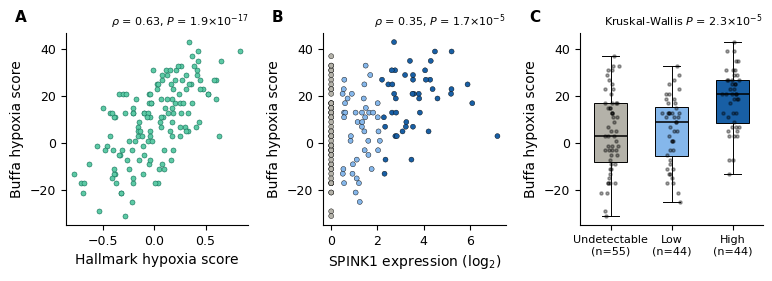

In [4]:
import matplotlib.pyplot as plt

plt.rcParams.update({'font.family': 'sans-serif', 'font.sans-serif': ['Arial', 'DejaVu Sans'],
                     'font.size': 9, 'axes.labelsize': 10, 'axes.linewidth': 0.8,
                     'axes.spines.top': False, 'axes.spines.right': False,
                     'legend.frameon': False, 'pdf.fonttype': 42})
PALETTE = {'Undetectable': '#B4B2A9', 'Low': '#85B7EB', 'High': '#185FA5'}

def p_label(p):
    m, e = f'{p:.1e}'.split('e')
    return f'$P$ = {m}$\\times$10$^{{{int(e)}}}$'

fig, ax = plt.subplots(1, 3, figsize=(7.8, 2.9))

r, p = spearmanr(df['Hallmark_Hypoxia'], df['BUFFA_HYPOXIA_SCORE'])
ax[0].scatter(df['Hallmark_Hypoxia'], df['BUFFA_HYPOXIA_SCORE'], s=13, color='#5DCAA5',
              edgecolors='#0F6E56', linewidths=0.4)
ax[0].set_xlabel('Hallmark hypoxia score')
ax[0].set_title(f'$\\rho$ = {r:.2f}, {p_label(p)}', loc='right', fontsize=8)

r, p = spearmanr(df['SPINK1'], df['BUFFA_HYPOXIA_SCORE'])
ax[1].scatter(df['SPINK1'], df['BUFFA_HYPOXIA_SCORE'], s=13, c=group.map(PALETTE),
              edgecolors='black', linewidths=0.3)
ax[1].set_xlabel('SPINK1 expression (log$_2$)')
ax[1].set_title(f'$\\rho$ = {r:.2f}, {p_label(p)}', loc='right', fontsize=8)

rng = np.random.default_rng(0)
vals = [v.values for v in buffa]
for i, (g, v) in enumerate(zip(GROUP_ORDER, vals)):
    ax[2].boxplot(v, positions=[i], widths=0.55, showfliers=False, patch_artist=True,
                  medianprops=dict(color='black', lw=1.1),
                  boxprops=dict(facecolor=PALETTE[g], edgecolor='black', lw=0.7),
                  whiskerprops=dict(lw=0.7), capprops=dict(lw=0.7))
    ax[2].scatter(rng.normal(i, 0.07, len(v)), v, s=5, color='black', alpha=0.35, zorder=3)
ax[2].set_xticks(range(3))
ax[2].set_xticklabels([f'{g}\n(n={len(v)})' for g, v in zip(GROUP_ORDER, vals)], fontsize=8)
ax[2].set_title(f'Kruskal-Wallis {p_label(kruskal(*vals).pvalue)}', loc='right', fontsize=8)

for a, label in zip(ax, 'ABC'):
    a.set_ylabel('Buffa hypoxia score')
    a.text(-0.28, 1.06, label, transform=a.transAxes, fontsize=11, fontweight='bold')
fig.tight_layout(w_pad=1.5)

for ext in ['png', 'pdf']:
    fig.savefig(os.path.join(RESULTS, f'Figure_3_hypoxia_validation.{ext}'),
                dpi=600, bbox_inches='tight')
plt.show()

In [5]:
rng = np.random.default_rng(42)
PRIMARY = ['BUFFA_HYPOXIA_SCORE', 'WINTER_HYPOXIA_SCORE']
COVARS = ['Myeloid', 'Mes_clean', 'Proliferation']

def rho(d, target, adjusted):
    if adjusted:
        return partial_spearman(d['SPINK1'], d[target], d[COVARS])[0]
    return spearmanr(d['SPINK1'], d[target])[0]

rows = []
for t in PRIMARY:
    for adjusted in [False, True]:
        obs = rho(df, t, adjusted)
        boot = np.array([rho(df.iloc[rng.choice(len(df), len(df), replace=True)], t, adjusted)
                         for _ in range(2000)])
        lo, hi = np.percentile(boot[np.isfinite(boot)], [2.5, 97.5])
        perm = np.array([rho(df.assign(SPINK1=rng.permutation(df['SPINK1'].values)), t, adjusted)
                         for _ in range(2000)])
        p_perm = (np.abs(perm) >= abs(obs)).mean()
        loo = [rho(df.drop(df.index[i]), t, adjusted) for i in range(len(df))]
        detectable = df[df['SPINK1'] > 0]
        q = df['SPINK1'].quantile([0.025, 0.975])
        trimmed = df[df['SPINK1'].between(q.iloc[0], q.iloc[1])]
        rows.append({'score': t.replace('_HYPOXIA_SCORE', ''),
                     'model': 'adjusted' if adjusted else 'raw', 'rho': round(obs, 3),
                     'CI95': f'[{lo:.3f}, {hi:.3f}]',
                     'p_perm': '<0.0005' if p_perm == 0 else f'{p_perm:.4f}',
                     'LOO_min': round(min(loo), 3), 'LOO_max': round(max(loo), 3),
                     'detectable_only': round(rho(detectable, t, adjusted), 3),
                     'n_det': len(detectable),
                     'trimmed': round(rho(trimmed, t, adjusted), 3)})

s10 = pd.DataFrame(rows)
s10.to_csv(os.path.join(RESULTS, 'Table_S10_robustness.csv'), index=False)
print(s10.to_string(index=False))

 score    model   rho           CI95  p_perm  LOO_min  LOO_max  detectable_only  n_det  trimmed
 BUFFA      raw 0.351 [0.191, 0.496] <0.0005    0.338    0.369            0.428     88    0.337
 BUFFA adjusted 0.334 [0.154, 0.488] <0.0005    0.312    0.359            0.522     88    0.331
WINTER      raw 0.363 [0.205, 0.503] <0.0005    0.349    0.381            0.435     88    0.339
WINTER adjusted 0.362 [0.191, 0.513] <0.0005    0.336    0.383            0.473     88    0.354
